# GPT-2 124M — full run on 2× H100 (FineWeb-Edu 10B)

Reads `log_full_run/log.txt` (train / val / hella) and `log_full_run/perf.csv` (per-step timing).
Run the cells top to bottom.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

LOG_DIR = "log_full_run"

# reference lines (same as Andrej's plot)
GPT2_124M_VAL = 3.2924     # OpenAI GPT-2 124M, FineWeb-Edu val loss
GPT2_124M_HELLA = 0.294463 # OpenAI GPT-2 124M, HellaSwag acc_norm
GPT3_124M_HELLA = 0.337    # GPT-3 paper, 124M (Small)

## 1. Parse `log.txt`
Each line is `<step> <kind> <value>`, kind ∈ {train, val, hella}.

In [2]:
streams = {"train": {}, "val": {}, "hella": {}}
with open(f"{LOG_DIR}/log.txt") as f:
    for line in f:
        step, kind, val = line.split()
        streams[kind][int(step)] = float(val)

def xy(d):
    s = sorted(d)
    return np.array(s), np.array([d[k] for k in s])

tr_x, tr_y = xy(streams["train"])
va_x, va_y = xy(streams["val"])
he_x, he_y = xy(streams["hella"])
print(f"train points: {len(tr_x)}, val points: {len(va_x)}, hella points: {len(he_x)}")
print(f"final val {va_y[-1]:.4f} (GPT-2 {GPT2_124M_VAL}), final hella {he_y[-1]:.4f} (GPT-2 {GPT2_124M_HELLA:.4f})")

train points: 19073, val points: 78, hella points: 78
final val 3.1511 (GPT-2 3.2924), final hella 0.2989 (GPT-2 0.2945)


## 2. Loss curves

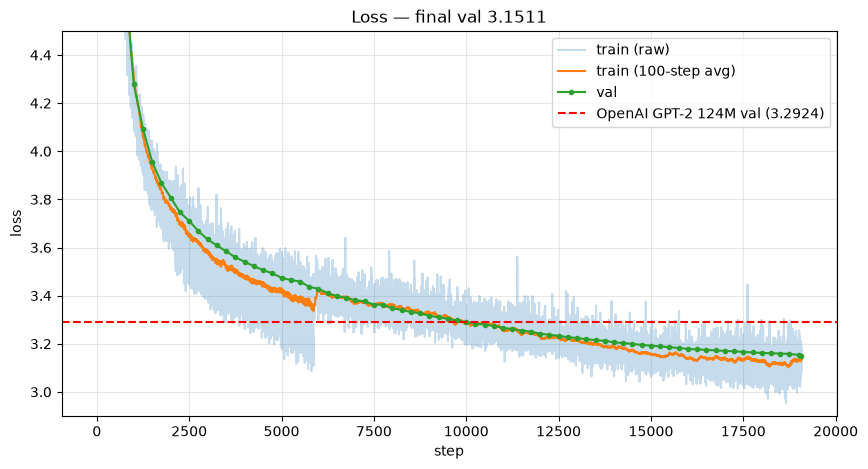

val loss first below GPT-2 at step 10000 (~5.2B tokens)


In [3]:
def smooth(y, k=100):
    # trailing moving average (each point = mean of previous k steps)
    c = np.cumsum(np.insert(y, 0, 0.0))
    s = (c[k:] - c[:-k]) / k
    return np.concatenate([y[:k-1], s])

plt.figure(figsize=(10, 5))
plt.plot(tr_x, tr_y, alpha=0.25, label="train (raw)")
plt.plot(tr_x, smooth(tr_y), label="train (100-step avg)")
plt.plot(va_x, va_y, "o-", ms=3, label="val")
plt.axhline(GPT2_124M_VAL, color="r", ls="--", label=f"OpenAI GPT-2 124M val ({GPT2_124M_VAL})")
plt.ylim(2.9, 4.5)
plt.xlabel("step"); plt.ylabel("loss"); plt.grid(alpha=0.3); plt.legend()
plt.title(f"Loss — final val {va_y[-1]:.4f}")
plt.show()

cross = va_x[np.argmax(va_y < GPT2_124M_VAL)]
print(f"val loss first below GPT-2 at step {cross} (~{cross * 524288 / 1e9:.1f}B tokens)")

## 3. HellaSwag

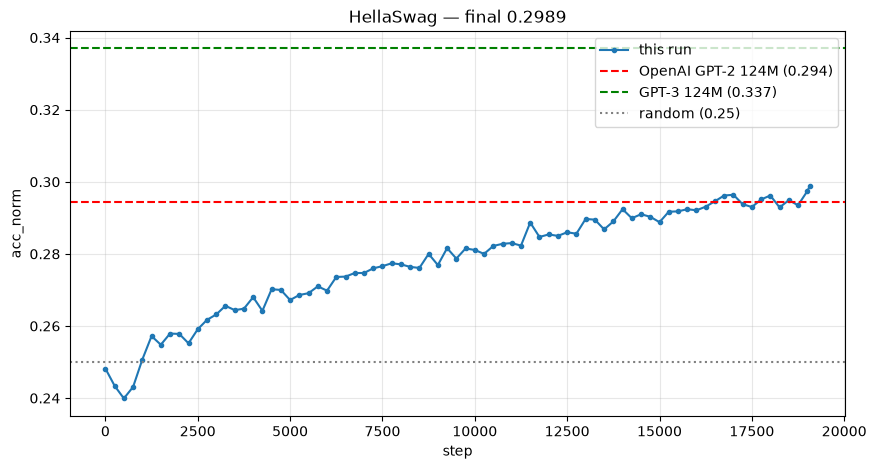

first eval above GPT-2: step 16500


In [4]:
plt.figure(figsize=(10, 5))
plt.plot(he_x, he_y, "o-", ms=3, label="this run")
plt.axhline(GPT2_124M_HELLA, color="r", ls="--", label=f"OpenAI GPT-2 124M ({GPT2_124M_HELLA:.3f})")
plt.axhline(GPT3_124M_HELLA, color="g", ls="--", label=f"GPT-3 124M ({GPT3_124M_HELLA})")
plt.axhline(0.25, color="gray", ls=":", label="random (0.25)")
plt.xlabel("step"); plt.ylabel("acc_norm"); plt.grid(alpha=0.3); plt.legend()
plt.title(f"HellaSwag — final {he_y[-1]:.4f}")
plt.show()

above = he_x[he_y > GPT2_124M_HELLA]
print(f"first eval above GPT-2: step {above[0] if len(above) else 'never'}")

## 4. The data-order jump around step ~5,900
Zoom in on the raw train loss. Val loss is unaffected → it's the data order, not the model.

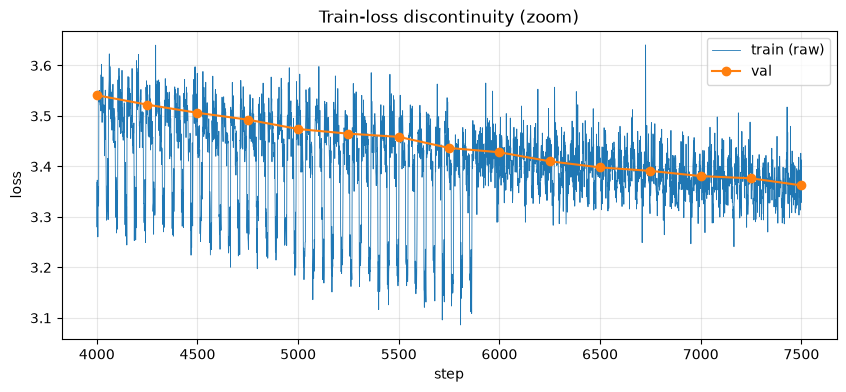

In [5]:
lo, hi = 4000, 7500
m = (tr_x >= lo) & (tr_x <= hi)
mv = (va_x >= lo) & (va_x <= hi)
plt.figure(figsize=(10, 4))
plt.plot(tr_x[m], tr_y[m], lw=0.6, label="train (raw)")
plt.plot(va_x[mv], va_y[mv], "o-", label="val")
plt.xlabel("step"); plt.ylabel("loss"); plt.grid(alpha=0.3); plt.legend()
plt.title("Train-loss discontinuity (zoom)")
plt.show()

## 5. Throughput from `perf.csv`
Line 1 is `# run_tag`, line 2 is the CSV header.

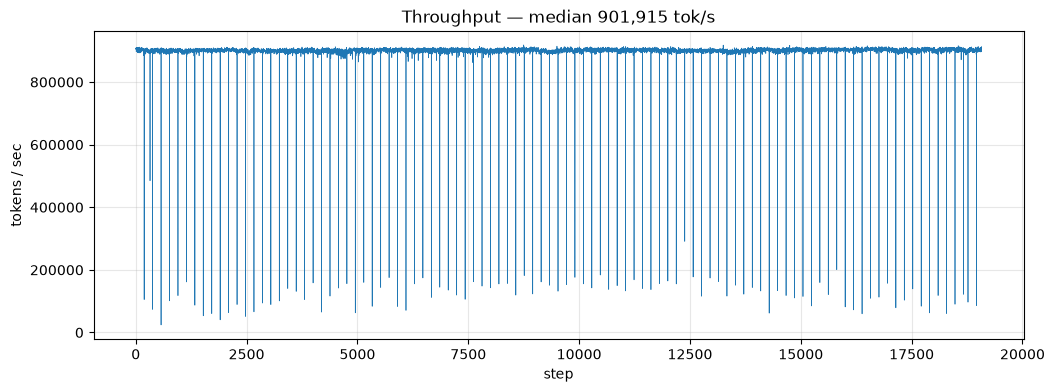

mean dt   604.8 ms
median dt 581.3 ms


In [6]:
perf = np.genfromtxt(f"{LOG_DIR}/perf.csv", delimiter=",", skip_header=1, names=True)
steps, dt, tok = perf["step"], perf["dt_ms"], perf["tok_per_sec"]
keep = steps >= 3   # skip compile warm-up

plt.figure(figsize=(12, 4))
plt.plot(steps[keep], tok[keep], lw=0.5)
plt.xlabel("step"); plt.ylabel("tokens / sec"); plt.grid(alpha=0.3)
plt.title(f"Throughput — median {np.median(tok[keep]):,.0f} tok/s")
plt.show()

print(f"mean dt   {dt[keep].mean():.1f} ms")
print(f"median dt {np.median(dt[keep]):.1f} ms")

## 6. The periodic stalls = shard loading
Find the slow steps and check their spacing against steps-per-shard = 100M / 524,288 ≈ 191.

slow steps: 100
median gap between slow steps: 190 steps (expected 190.7)
first few: [ 190  380  571  761  952 1142 1333 1523]
time lost to stalls: 7.4 min of 192.2 min training (3.8%)


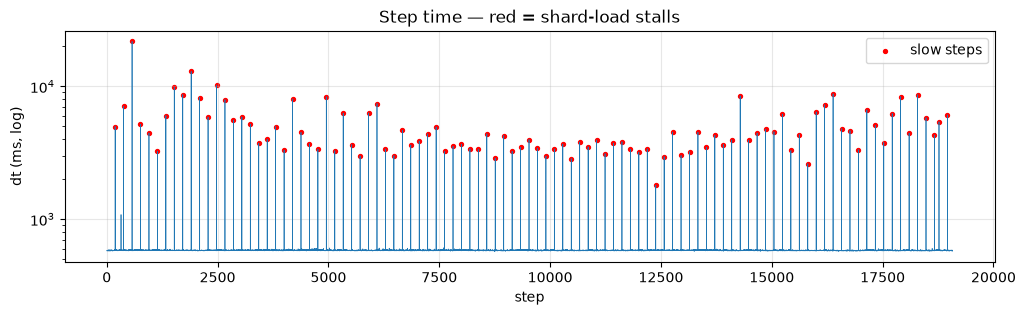

In [7]:
slow = steps[keep][dt[keep] > 2 * np.median(dt[keep])].astype(int)
gaps = np.diff(slow)
print(f"slow steps: {len(slow)}")
print(f"median gap between slow steps: {np.median(gaps):.0f} steps (expected {100e6 / 524288:.1f})")
print(f"first few: {slow[:8]}")

extra_s = (dt[keep][dt[keep] > 2 * np.median(dt[keep])] - np.median(dt[keep])).sum() / 1000
total_s = dt[keep].sum() / 1000
print(f"time lost to stalls: {extra_s/60:.1f} min of {total_s/60:.1f} min training ({100*extra_s/total_s:.1f}%)")

plt.figure(figsize=(12, 3))
plt.plot(steps[keep], dt[keep], lw=0.5)
plt.scatter(slow, dt[np.isin(steps, slow)], color="r", s=8, label="slow steps")
plt.yscale("log"); plt.xlabel("step"); plt.ylabel("dt (ms, log)"); plt.grid(alpha=0.3); plt.legend()
plt.title("Step time — red = shard-load stalls")
plt.show()

## 7. Predicted vs actual

In [8]:
start, end = "01:41:42", "05:36:16"   # from train_start.txt / train_end.txt (UTC)
h = lambda t: sum(int(x) * 60**i for i, x in enumerate(reversed(t.split(":")))) / 3600
wall_h = h(end) - h(start)
train_h = dt[keep].sum() / 1000 / 3600
print(f"wall clock      {wall_h:.2f} h  (predicted ~4.1 h at 11 min in)")
print(f"pure training   {train_h:.2f} h")
print(f"evals + other   {wall_h - train_h:.2f} h ({100*(wall_h-train_h)/wall_h:.0f}%)")
print(f"GPU cost (run only) ≈ ${wall_h * 7.99:.2f}")

wall clock      3.91 h  (predicted ~4.1 h at 11 min in)
pure training   3.20 h
evals + other   0.71 h (18%)
GPU cost (run only) ≈ $31.24
